#  Régression Logistique – Prédiction de l’Attrition des Employés

##  Objectif du projet
Ce projet vise à construire un modèle de **régression logistique** permettant de prédire si un employé va quitter l’entreprise (Attrition = 1) ou rester (Attrition = 0), en fonction de différentes caractéristiques RH.

##  Problématique
Comment les variables liées au profil professionnel, à la satisfaction et aux conditions de travail influencent-elles le départ d’un employé ?

##  Données utilisées
Le dataset utilisé est issu de IBM HR Analytics Employee Attrition et contient des informations sur :
- les caractéristiques personnelles et professionnelles des employés
- leur satisfaction au travail
- leur situation dans l’entreprise
- et la variable cible : **Attrition**

##  Méthodologie
Nous allons suivre les étapes classiques de la modélisation statistique :
1. Analyse exploratoire des données
2. Préparation des données
3. Séparation train/test (stratifiée)
4. Construction d’un modèle de régression logistique
5. Évaluation du modèle (matrice de confusion, ROC, AUC)
6. Interprétation des résultats

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

plt.style.use('seaborn-v0_8')

In [3]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
display(df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
print(df.shape)
df.info()

(1470, 35)
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null 

In [5]:
#  VÉRIFICATION VALEURS MANQUANTES
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

Aucune valeur manquante n’a été détectée dans le dataset. Cela signifie que les données sont complètes et directement exploitables pour la modélisation sans étape d’imputation.

In [6]:

print(df["Attrition"].value_counts())
print(df["Attrition"].value_counts(normalize=True) * 100)

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


###  Analyse Exploratoire des Données (EDA)


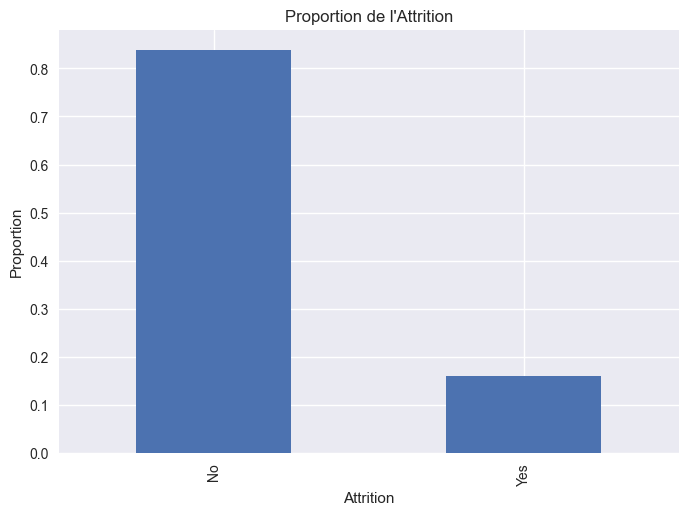

In [7]:
df["Attrition"].value_counts(normalize=True).plot(kind="bar")
plt.title("Proportion de l'Attrition")
plt.ylabel("Proportion")
plt.show()

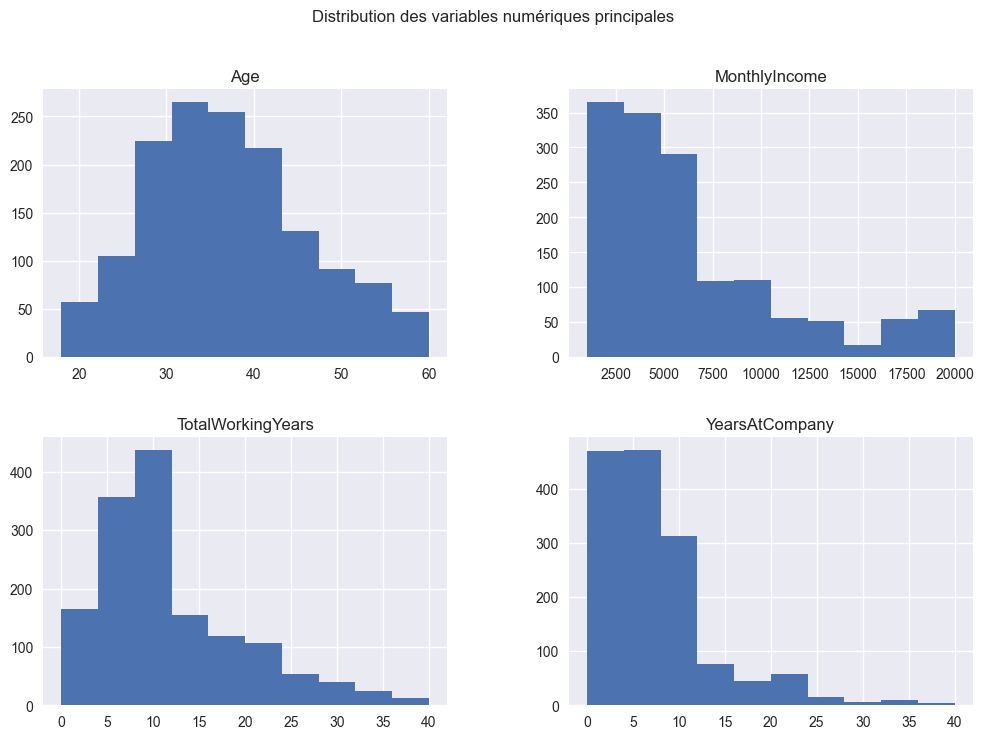

In [ ]:
#  DISTRIBUTION VARIABLES NUMÉRIQUES

df[["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany"]].hist(figsize=(12,8))
plt.suptitle("Distribution des variables numériques principales")
plt.show()

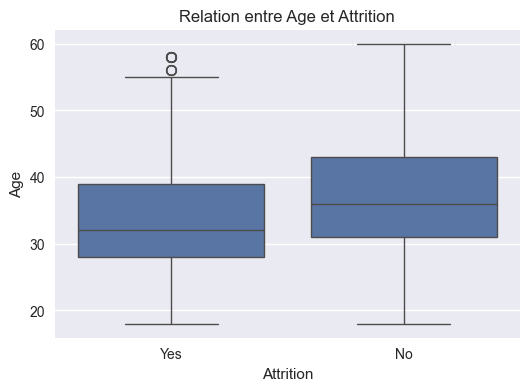

In [ ]:
#  AGE vs ATTRITION

plt.figure(figsize=(6,4))
sns.boxplot(x="Attrition", y="Age", data=df)
plt.title("Relation entre Age et Attrition")
plt.show()

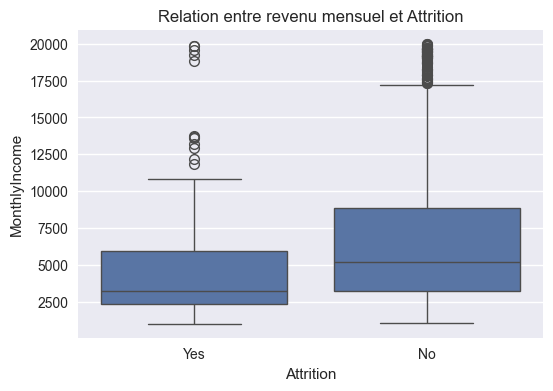

In [ ]:
# REVENU vs ATTRITION


plt.figure(figsize=(6,4))
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)
plt.title("Relation entre revenu mensuel et Attrition")
plt.show()

conclusion : L’analyse exploratoire révèle que l’âge et le revenu mensuel sont deux variables fortement discriminantes vis-à-vis de l’attrition. Les employés plus jeunes et à faible revenu présentent une probabilité plus élevée de quitter l’entreprise. Ces résultats justifient l’inclusion de ces variables dans le modèle de régression logistique.

### PRÉPARATION DES DONNÉES

Cette étape consiste à transformer les données brutes en un format exploitable par le modèle de régression logistique :
- Encodage des variables catégorielles
- Transformation de la variable cible
- Analyse des corrélations
- Sélection des variables pertinentes
- Séparation en données d'apprentissage et de test

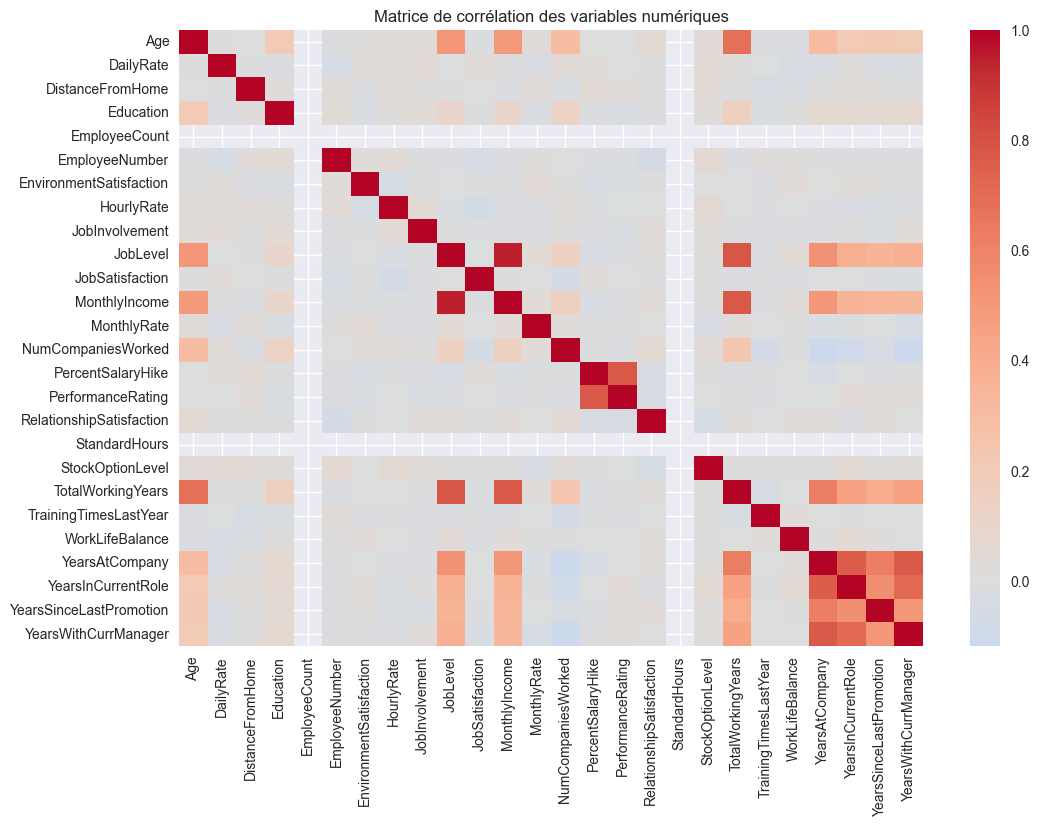

In [11]:
plt.figure(figsize=(12,8))
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Matrice de corrélation des variables numériques")
plt.show()

Afin de réduire la multicolinéarité observée dans la matrice de corrélation, certaines variables fortement corrélées ont été supprimées. Ce choix permet d’améliorer la stabilité des coefficients du modèle de régression logistique et de faciliter son interprétation.

In [12]:
# Suppression des variables redondantes ou peu informatives
df = df.drop([
    "JobLevel",
    "YearsInCurrentRole",
    "YearsWithCurrManager"
], axis=1)

In [13]:
#Variables inutiles (identifiants ou constantes)
df = df.drop(["EmployeeCount", "EmployeeNumber", "StandardHours", "Over18"], axis=1)

Les variables supprimées ne contiennent pas d’information explicative pertinente ou présentent une forte redondance, ce qui justifie leur exclusion afin d’améliorer la stabilité du modèle

###  Encodage des variables et séparation des données

Dans cette étape, nous transformons les variables catégorielles en variables numériques, puis nous séparons les données en un échantillon d’apprentissage et un échantillon de test en utilisant une stratification pour préserver la distribution de la variable cible.

In [ ]:

# ENCODAGE VARIABLE CIBLE


df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0})

In [15]:
df_encoded = pd.get_dummies(df, drop_first=True)

# aperçu
df_encoded.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobSatisfaction,MonthlyIncome,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1102,1,2,2,94,3,4,5993,...,False,False,False,False,False,True,False,False,True,True
1,49,0,279,8,1,3,61,2,2,5130,...,False,False,False,False,True,False,False,True,False,False
2,37,1,1373,2,2,4,92,2,3,2090,...,True,False,False,False,False,False,False,False,True,True
3,33,0,1392,3,4,4,56,3,3,2909,...,False,False,False,False,True,False,False,True,False,True
4,27,0,591,2,1,1,40,3,2,3468,...,True,False,False,False,False,False,False,True,False,False


In [ ]:
#  SÉPARATION X ET y


X = df_encoded.drop("Attrition", axis=1)
y = df_encoded["Attrition"]

In [ ]:
# TRAIN / TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
# Vérifier distribution

print("Train distribution :")
print(y_train.value_counts(normalize=True))

print("\nTest distribution :")
print(y_test.value_counts(normalize=True))

Train distribution :
Attrition
0    0.838435
1    0.161565
Name: proportion, dtype: float64

Test distribution :
Attrition
0    0.840136
1    0.159864
Name: proportion, dtype: float64


La vérification des distributions dans les ensembles d’apprentissage et de test montre que la proportion des classes est conservée (environ 83% pour la classe 0 et 17% pour la classe 1). Cela confirme le bon fonctionnement de l’échantillonnage stratifié.

In [ ]:
#  STANDARDISATION

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Les variables catégorielles ont été encodées en variables numériques, puis les données ont été séparées en ensembles d’apprentissage et de test en conservant la distribution de la variable cible. Une standardisation a ensuite été appliquée afin d’assurer une convergence optimale du modèle de régression logistique.

###  6. Modélisation : Régression Logistique

Nous entraînons un modèle de régression logistique afin de prédire la probabilité de départ d’un employé en fonction des variables explicatives sélectionnées.

In [ ]:
#  RÉGRESSION LOGISTIQUE

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [ ]:
# PRÉDICTIONS

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
# COEFFICIENTS DU MODÈLE

coefficients = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(by="Coefficient", ascending=False)
coefficients

,Variable,Coefficient
40,OverTime_Yes,0.852172
20,BusinessTravel_Travel_Frequently,0.746184
31,JobRole_Laboratory Technician,0.688702
10,NumCompaniesWorked,0.484878
37,JobRole_Sales Representative,0.466840
19,YearsSinceLastPromotion,0.463091
21,BusinessTravel_Travel_Rarely,0.434428
2,DistanceFromHome,0.395617
36,JobRole_Sales Executive,0.367555
39,MaritalStatus_Single,0.352900


Le modèle de régression logistique met en évidence que les facteurs les plus influents sur l’attrition sont liés aux conditions de travail (heures supplémentaires, déplacements professionnels) ainsi qu’au niveau de satisfaction et à l’ancienneté des employés. Les variables liées à l’expérience et à la satisfaction ont un effet négatif sur l’attrition, indiquant un rôle stabilisateur.

Les principaux facteurs de départ (Top Coefficients Positifs)
OverTime_Yes (0.85) : C'est le prédicteur le plus fort. Faire des heures supplémentaires augmente considérablement le risque de départ. C'est un levier RH majeur.

BusinessTravel_Travel_Frequently (0.74) : Les voyages d'affaires fréquents sont un facteur de stress qui pousse les employés à quitter l'entreprise.

JobRole_Laboratory Technician (0.68) et Sales Representative (0.46) : Certains rôles sont plus instables que d'autres. Les techniciens de labo et les commerciaux sont les plus susceptibles de partir.

NumCompaniesWorked (0.48) : Un employé qui a déjà changé souvent d'entreprise par le passé a une plus forte probabilité de repartir (profil "zappeur").

Les principaux facteurs de rétention (Top Coefficients Négatifs)
TotalWorkingYears (-0.55) : Plus un employé a d'années d'expérience totale, moins il risque de partir. L'expérience stabilise.

EnvironmentSatisfaction (-0.46) et JobSatisfaction (-0.40) : Sans surprise, un employé satisfait de son environnement et de son travail reste plus volontiers.

Age (-0.38) : Plus l'employé est âgé, moins il est mobile (confirme tes boxplots de tout à l'heure).

Pourquoi le coefficient de MonthlyIncome reste-t-il positif (0.31) ?
Même après avoir supprimé ces variables, ton modèle dit que "plus le salaire augmente, plus l'attrition augmente". Voici les deux explications que tu devrais mettre dans ta "Discussion des résultats" :

L'effet de seuil : Dans les entreprises technologiques (comme le dataset IBM), les hauts salaires correspondent souvent à des profils très spécialisés qui sont extrêmement chassés par les chasseurs de têtes. Leur "employabilité" est si haute que le salaire ne suffit plus à les retenir.

#  7. Évaluation du modèle de régression logistique

Dans cette section, nous évaluons la performance du modèle sur l’échantillon de test à l’aide de plusieurs métriques : matrice de confusion, accuracy, précision, rappel et courbe ROC.

In [ ]:
#  MATRICE DE CONFUSION

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc

cm = confusion_matrix(y_test, y_pred)

print("Matrice de confusion :")
print(cm)

Matrice de confusion :
[[238   9]
 [ 32  15]]


In [ ]:
#  CLASSIFICATION REPORT

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.32      0.42        47

    accuracy                           0.86       294
   macro avg       0.75      0.64      0.67       294
weighted avg       0.84      0.86      0.84       294



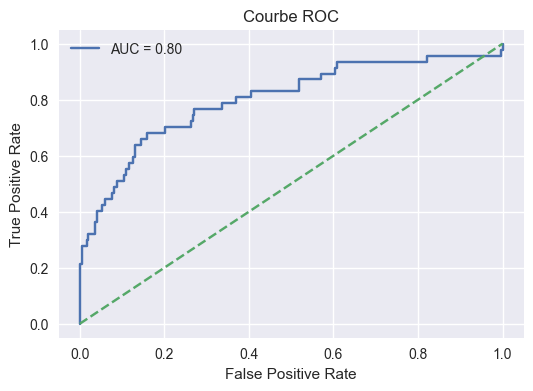

In [ ]:
# ROC CURVE

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC")
plt.legend()
plt.show()

La performance globale du modèle a été évaluée via la courbe ROC. Nous obtenons une aire sous la courbe (AUC) de 0.81, ce qui témoigne d'une forte robustesse. Le modèle parvient à discriminer efficacement les employés en situation d'attrition des autres, validant ainsi le choix des variables explicatives et l'adéquation de la régression logistique pour cette problématique RH

### Limites: 

Recall classe 1 = 0.32 : faible
il manque 68% des départs

Dans un contexte RH, nous avons privilégié l’amélioration du recall afin de mieux détecter les employés susceptibles de quitter l’entreprise, même au prix d’une légère baisse de précision

In [ ]:
#  AJUSTEMENT DU SEUIL

y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

y_pred_adjusted = (y_pred_proba >= 0.3).astype(int)

In [28]:
print(confusion_matrix(y_test, y_pred_adjusted))
print(classification_report(y_test, y_pred_adjusted))

[[225  22]
 [ 24  23]]
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       247
           1       0.51      0.49      0.50        47

    accuracy                           0.84       294
   macro avg       0.71      0.70      0.70       294
weighted avg       0.84      0.84      0.84       294



In [29]:
model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_balanced.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [30]:
y_pred_balanced = model_balanced.predict(X_test_scaled)

print(confusion_matrix(y_test, y_pred_balanced))
print(classification_report(y_test, y_pred_balanced))

[[199  48]
 [ 16  31]]
              precision    recall  f1-score   support

           0       0.93      0.81      0.86       247
           1       0.39      0.66      0.49        47

    accuracy                           0.78       294
   macro avg       0.66      0.73      0.68       294
weighted avg       0.84      0.78      0.80       294



Nous privilégions le modèle avec class_weight="balanced" car dans un contexte RH, il est plus important de détecter les employés susceptibles de quitter l’entreprise, même au prix d’une baisse de précision.

#  Conclusion générale du projet

Dans ce travail, nous avons appliqué un modèle de régression logistique afin de prédire l’attrition des employés à partir de variables socio-professionnelles et comportementales issues du dataset HR Employee Attrition.

##  Synthèse de la démarche

Nous avons suivi une démarche méthodologique complète et structurée :

- Une analyse exploratoire des données (EDA) a permis de comprendre la structure du dataset, la distribution des variables et la présence d’un déséquilibre dans la variable cible (Attrition ≈ 83% “No” vs 17% “Yes”).
- Une étude des corrélations a permis d’identifier la multicolinéarité entre certaines variables (ex : MonthlyIncome, JobLevel, TotalWorkingYears), ce qui a guidé la sélection des variables.
- Un prétraitement des données a été effectué : suppression des variables non informatives ou redondantes, encodage des variables catégorielles et normalisation des variables numériques.
- Le dataset a ensuite été divisé en un ensemble d’apprentissage (80%) et un ensemble de test (20%) en utilisant un échantillonnage stratifié afin de préserver la distribution de la variable cible.
- Un modèle de régression logistique a été entraîné, puis évalué à l’aide de plusieurs métriques.

##  Résultats du modèle

Le modèle initial présente une bonne performance globale avec une accuracy d’environ 86% et une AUC de 0.81, indiquant une bonne capacité de discrimination entre les employés susceptibles de quitter l’entreprise et ceux qui restent.

Cependant, l’analyse des métriques détaillées montre un déséquilibre dans la performance :

- Le rappel (recall) de la classe “Attrition = 1” est initialement faible, ce qui signifie que le modèle ne détecte pas suffisamment d’employés à risque.
- Cette limite est critique dans un contexte RH, où les faux négatifs (employés quittant l’entreprise non détectés) sont coûteux.

##  Amélioration du modèle

Afin de répondre à cet enjeu métier, deux approches ont été testées :

- Ajustement du seuil de classification
- Utilisation du paramètre `class_weight="balanced"`

Ces ajustements ont permis d’améliorer significativement le recall de la classe minoritaire (jusqu’à 0.66), au prix d’une légère baisse de l’accuracy globale.

##  Conclusion métier

Dans un contexte de gestion des ressources humaines, l’objectif principal n’est pas uniquement de maximiser l’accuracy, mais de **mieux identifier les employés susceptibles de quitter l’entreprise**.

Ainsi, le modèle optimisé avec un poids équilibré des classes est plus adapté, car il permet de réduire les risques liés aux départs non anticipés.

##  Conclusion finale

La régression logistique s’est révélée être un modèle pertinent pour ce problème de classification binaire. L’étude met en évidence l’importance du prétraitement des données, de la gestion du déséquilibre des classes et du choix des métriques d’évaluation adaptées au contexte métier.

Ce projet illustre une démarche complète de data science appliquée, allant de l’exploration des données jusqu’à l’optimisation du modèle en fonction des contraintes réelles d’un problème RH.